In [1]:
from datetime import date, datetime
from dateutil.rrule import rrule, DAILY

from matplotlib import pyplot
%matplotlib inline

import numpy as np
import pandas as pd

import scipy.stats as ss
from sklearn import linear_model
import statsmodels.api as sm

In [2]:
df_vitals = pd.read_csv('vitals2.csv')

C:\ProgramData\Anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3058: DtypeWarning: Columns (9,10,11,22,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  interactivity=interactivity, compiler=compiler, result=result)


In [3]:
df_vitals.head()

,created,eventTypeAndTimestamp,patient_uuid,timestamp,updated,BPM,DBP,DistanceTravel,FAHR,FAST,...,TimeAwake,TimeInBed,TimeSleep,device,deviceId,deviceModel,deviceVendor,height,identifier,location
0,NaN,VITALS-1451632080000,82591262,2015-12-31 23:08:00,NaN,NaN,112.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
1,NaN,VITALS-1539117600000,82591262,2018-10-09 13:40:00,NaN,NaN,72.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
2,NaN,VITALS-1539131940000,82591262,2018-10-09 17:39:00,NaN,NaN,84.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
3,NaN,VITALS-1539132000000,82591262,2018-10-09 17:40:00,NaN,NaN,79.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
4,NaN,VITALS-1539184020000,82591262,2018-10-10 08:07:00,NaN,NaN,88.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device


In [4]:
#convert the timestamp field from string to datetime data type
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'],errors='coerce')

In [5]:
df_vitals.head()

,created,eventTypeAndTimestamp,patient_uuid,timestamp,updated,BPM,DBP,DistanceTravel,FAHR,FAST,...,TimeAwake,TimeInBed,TimeSleep,device,deviceId,deviceModel,deviceVendor,height,identifier,location
0,NaN,VITALS-1451632080000,82591262,2015-12-31 23:08:00,NaN,NaN,112.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
1,NaN,VITALS-1539117600000,82591262,2018-10-09 13:40:00,NaN,NaN,72.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
2,NaN,VITALS-1539131940000,82591262,2018-10-09 17:39:00,NaN,NaN,84.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
3,NaN,VITALS-1539132000000,82591262,2018-10-09 17:40:00,NaN,NaN,79.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device
4,NaN,VITALS-1539184020000,82591262,2018-10-10 08:07:00,NaN,NaN,88.0,NaN,NaN,NaN,...,NaN,NaN,NaN,MocaCuff,NaN,NaN,NaN,NaN,NaN,device


In [6]:
# keep only the required fields 
df_vitals=df_vitals[['patient_uuid','timestamp','HR','SBP','DBP']]

In [7]:
df_vitals.head()

,patient_uuid,timestamp,HR,SBP,DBP
0,82591262,2015-12-31 23:08:00,67.0,161.0,112.0
1,82591262,2018-10-09 13:40:00,80.0,111.0,72.0
2,82591262,2018-10-09 17:39:00,79.0,134.0,84.0
3,82591262,2018-10-09 17:40:00,79.0,126.0,79.0
4,82591262,2018-10-10 08:07:00,53.0,137.0,88.0


In [8]:
# remove entries older than 2018 and newer than 11-Nov-2019. This step may or may not be needed.
# retaining it as-is for now
df_vitals=df_vitals[(df_vitals.timestamp>'2018-01-01')&(df_vitals.timestamp<'2019-11-11')]

# remove all na entries
df_vitals=df_vitals[~df_vitals['DBP'].isna()]
df_vitals=df_vitals[~df_vitals['SBP'].isna()]
df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [9]:
# Let's start our analysis with the Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']]

In [10]:
df_vitals_sbp

,timestamp,patient_uuid,SBP
1,2018-10-09 13:40:00.000000,82591262,111.0
2,2018-10-09 17:39:00.000000,82591262,134.0
3,2018-10-09 17:40:00.000000,82591262,126.0
4,2018-10-10 08:07:00.000000,82591262,137.0
5,2018-10-10 14:02:00.000000,82591262,134.0
...,...,...,...
141927,2019-11-02 10:38:59.759999,81827529,126.0
141928,2019-11-02 14:17:59.759999,81827529,122.0
141929,2019-11-03 10:28:59.700000,81827529,127.0
141930,2019-11-03 15:17:59.700000,81827529,135.0


In [11]:
df_vitals_sbp_day = df_vitals_sbp

df_vitals_sbp_day['reading_date'] = [dt.date() for dt in df_vitals_sbp_day.timestamp]

df_vitals_sbp_day = df_vitals_sbp_day.groupby(['patient_uuid','reading_date']).filter(lambda x : len(x)>1)

df_vitals_sbp_day

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  This is separate from the ipykernel package so we can avoid doing imports until


,timestamp,patient_uuid,SBP,reading_date
1,2018-10-09 13:40:00.000000,82591262,111.0,2018-10-09
2,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09
3,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09
4,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-10
5,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-10
...,...,...,...,...
141926,2019-11-01 12:51:59.759999,81827529,137.0,2019-11-01
141927,2019-11-02 10:38:59.759999,81827529,126.0,2019-11-02
141928,2019-11-02 14:17:59.759999,81827529,122.0,2019-11-02
141929,2019-11-03 10:28:59.700000,81827529,127.0,2019-11-03


In [12]:
df_vitals_sbp_day

,timestamp,patient_uuid,SBP,reading_date
1,2018-10-09 13:40:00.000000,82591262,111.0,2018-10-09
2,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09
3,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09
4,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-10
5,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-10
...,...,...,...,...
141926,2019-11-01 12:51:59.759999,81827529,137.0,2019-11-01
141927,2019-11-02 10:38:59.759999,81827529,126.0,2019-11-02
141928,2019-11-02 14:17:59.759999,81827529,122.0,2019-11-02
141929,2019-11-03 10:28:59.700000,81827529,127.0,2019-11-03


In [13]:
df_vitals_sbp_day = pd.DataFrame(df_vitals_sbp_day.groupby(['patient_uuid','reading_date']).agg({'SBP' : np.mean}))

df_vitals_sbp_day['source'] = 1

In [14]:
df_vitals_sbp_day

SBP  source
patient_uuid reading_date                    
1048697      2019-08-27    123.000000       1
             2019-08-28    113.000000       1
             2019-08-29    125.333333       1
             2019-08-30    122.000000       1
             2019-08-31    106.000000       1
...                               ...     ...
99726731     2019-02-21    118.500000       1
             2019-03-01    116.000000       1
             2019-03-06    115.000000       1
             2019-03-16    123.333333       1
             2019-03-23    125.500000       1

[41498 rows x 2 columns]

In [15]:
# extend the dataset to have a new field 
# that contains the date time value of the very first measurement available for each patient
# this information will later be used to derive additional column values of interest

df_vitals_sbp_minmaxtimes = pd.DataFrame(df_vitals_sbp.groupby('patient_uuid').agg({'timestamp' : np.min}))

df_vitals_sbp_minmaxtimes['timestamp'] = df_vitals_sbp_minmaxtimes['timestamp']

df_vitals_sbp_extended = pd.merge(df_vitals_sbp, df_vitals_sbp_minmaxtimes, on='patient_uuid')

In [16]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y
0,2018-10-09 13:40:00.000000,82591262,111.0,2018-10-09,2018-10-09 13:40:00.000000
1,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09,2018-10-09 13:40:00.000000
2,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09,2018-10-09 13:40:00.000000
3,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-10,2018-10-09 13:40:00.000000
4,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-10,2018-10-09 13:40:00.000000
...,...,...,...,...,...
140789,2019-11-02 10:38:59.759999,81827529,126.0,2019-11-02,2019-09-24 12:36:59.759999
140790,2019-11-02 14:17:59.759999,81827529,122.0,2019-11-02,2019-09-24 12:36:59.759999
140791,2019-11-03 10:28:59.700000,81827529,127.0,2019-11-03,2019-09-24 12:36:59.759999
140792,2019-11-03 15:17:59.700000,81827529,135.0,2019-11-03,2019-09-24 12:36:59.759999


In [17]:
# In the extended dataset, add two additional columns that have the measurement date (without the time)
# and the start date (without the time)
# Again, this information will be used subsequently to derive additional features of interest
df_vitals_sbp_extended['reading_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_x]

df_vitals_sbp_extended['reading_start_date'] = [dt.date() for dt in df_vitals_sbp_extended.timestamp_y]

In [18]:
# for every reading, get the days elapsed since the first measurement date (note this is in days)
df_vitals_sbp_extended['days_elapsed'] = (df_vitals_sbp_extended['reading_date'] - df_vitals_sbp_extended['reading_start_date']).dt.days

In [19]:
# convert the new time stamp columns to date time data type
df_vitals_sbp_extended['timestamp_x'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_x'])
df_vitals_sbp_extended['timestamp_y'] = pd.to_datetime(df_vitals_sbp_extended['timestamp_y'])

In [20]:
# Now, from the time component, get the hours since mid night for each measurement
# and extend it further to get the corresponding angle (24 hours = 360 degress, x hours = x*360/24)

df_vitals_sbp_extended['elapsed_time'] = df_vitals_sbp_extended['timestamp_x'] - df_vitals_sbp_extended['timestamp_y']
df_vitals_sbp_extended['angle'] = df_vitals_sbp_extended['elapsed_time'].diff() *360 / (np.timedelta64(1, 'h') *24)

# get the cosine and sine values corresponding to these angles
df_vitals_sbp_extended['sine'] = np.sin(df_vitals_sbp_extended['angle'])
df_vitals_sbp_extended['cos'] = np.cos(df_vitals_sbp_extended['angle'])

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos'].isna()]


# get the cosine and sine values corresponding to the angles with a period T/2 = 12 hours
df_vitals_sbp_extended['sine.Tby2'] = np.sin(df_vitals_sbp_extended['angle']*2)
df_vitals_sbp_extended['cos.Tby2'] = np.cos(df_vitals_sbp_extended['angle']*2)

# drop NA
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['sine.Tby2'].isna()]
df_vitals_sbp_extended=df_vitals_sbp_extended[~df_vitals_sbp_extended['cos.Tby2'].isna()]

In [21]:
df_vitals_sbp_extended

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2
1,2018-10-09 17:39:00.000000,82591262,134.0,2018-10-09,2018-10-09 13:40:00.000000,2018-10-09,0,0 days 03:59:00,59.75000,-0.059704,-0.998216,0.119195,0.992871
2,2018-10-09 17:40:00.000000,82591262,126.0,2018-10-09,2018-10-09 13:40:00.000000,2018-10-09,0,0 days 04:00:00,0.25000,0.247404,0.968912,0.479426,0.877583
3,2018-10-10 08:07:00.000000,82591262,137.0,2018-10-10,2018-10-09 13:40:00.000000,2018-10-09,1,0 days 18:27:00,216.75000,0.019892,-0.999802,-0.039776,0.999209
4,2018-10-10 14:02:00.000000,82591262,134.0,2018-10-10,2018-10-09 13:40:00.000000,2018-10-09,1,1 days 00:22:00,88.75000,0.707112,0.707101,1.000000,-0.000015
5,2018-10-10 17:14:00.000000,82591262,163.0,2018-10-10,2018-10-09 13:40:00.000000,2018-10-09,1,1 days 03:34:00,48.00000,-0.768255,-0.640144,0.983588,-0.180430
...,...,...,...,...,...,...,...,...,...,...,...,...,...
140789,2019-11-02 10:38:59.759999,81827529,126.0,2019-11-02,2019-09-24 12:36:59.759999,2019-09-24,39,38 days 22:02:00,326.75000,0.024362,0.999703,0.048709,0.998813
140790,2019-11-02 14:17:59.759999,81827529,122.0,2019-11-02,2019-09-24 12:36:59.759999,2019-09-24,39,39 days 01:41:00,54.75000,-0.974149,-0.225904,0.440129,-0.897934
140791,2019-11-03 10:28:59.700000,81827529,127.0,2019-11-03,2019-09-24 12:36:59.759999,2019-09-24,40,39 days 21:51:59.940001,302.74975,0.915543,0.402221,0.736500,-0.676437
140792,2019-11-03 15:17:59.700000,81827529,135.0,2019-11-03,2019-09-24 12:36:59.759999,2019-09-24,40,40 days 02:40:59.940001,72.25000,0.006631,-0.999978,-0.013262,0.999912


In [22]:
# create a new column and extract the information on days between the current measurement and the previous measurement
df_vitals_sbp_extended['days_between_readings'] = -999

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['days_elapsed']).shift(1)

In [23]:
# review this data for one patient just to make sure that the derived columns have the correct values
df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == 82591262]

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,days_between_readings
1,2018-10-09 17:39:00,82591262,134.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0 days 03:59:00,59.75,-0.059704,-0.998216,0.119195,0.992871,NaN
2,2018-10-09 17:40:00,82591262,126.0,2018-10-09,2018-10-09 13:40:00,2018-10-09,0,0 days 04:00:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0
3,2018-10-10 08:07:00,82591262,137.0,2018-10-10,2018-10-09 13:40:00,2018-10-09,1,0 days 18:27:00,216.75,0.019892,-0.999802,-0.039776,0.999209,1.0
4,2018-10-10 14:02:00,82591262,134.0,2018-10-10,2018-10-09 13:40:00,2018-10-09,1,1 days 00:22:00,88.75,0.707112,0.707101,1.000000,-0.000015,0.0
5,2018-10-10 17:14:00,82591262,163.0,2018-10-10,2018-10-09 13:40:00,2018-10-09,1,1 days 03:34:00,48.00,-0.768255,-0.640144,0.983588,-0.180430,0.0
6,2018-10-10 18:59:00,82591262,147.0,2018-10-10,2018-10-09 13:40:00,2018-10-09,1,1 days 05:19:00,26.25,0.898903,0.438148,0.787705,-0.616052,0.0
7,2018-10-11 04:35:00,82591262,154.0,2018-10-11,2018-10-09 13:40:00,2018-10-09,2,1 days 14:55:00,144.00,-0.491022,0.871147,-0.855504,0.517796,1.0
8,2018-10-11 20:15:00,82591262,141.0,2018-10-11,2018-10-09 13:40:00,2018-10-09,2,2 days 06:35:00,235.00,0.580587,-0.814198,-0.945426,0.325838,0.0
9,2018-10-11 20:16:00,82591262,133.0,2018-10-11,2018-10-09 13:40:00,2018-10-09,2,2 days 06:36:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0
10,2018-10-12 09:37:00,82591262,138.0,2018-10-12,2018-10-09 13:40:00,2018-10-09,3,2 days 19:57:00,200.25,-0.725616,0.688099,-0.998592,-0.053038,1.0


In [24]:
# Now, we will split the measurements for each patients into multiple batches
# the batch contains successive measurements with a gap of no more than 3 days between two readings
# If the gap is higher, then there could be a big change that will throw off the interpolation
# the 3 here is a hyperparameter which may need to be tuned
df_vitals_sbp_extended['batch'] = 0

df_vitals_sbp_extended.loc[df_vitals_sbp_extended['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_sbp_extended.loc[df_vitals_sbp_extended.patient_uuid == patient_uuid,'batch'] = df_vitals_sbp_extended[df_vitals_sbp_extended.patient_uuid == patient_uuid]['batch'].cumsum()

In [25]:
df_vitals_sbp_extended.head(60)

,timestamp_x,patient_uuid,SBP,reading_date,timestamp_y,reading_start_date,days_elapsed,elapsed_time,angle,sine,cos,sine.Tby2,cos.Tby2,days_between_readings,batch
1,2018-10-09 17:39:00.000,82591262,134.0,2018-10-09,2018-10-09 13:40:00.000,2018-10-09,0,0 days 03:59:00,59.75,-0.059704,-0.998216,0.119195,0.992871,NaN,0
2,2018-10-09 17:40:00.000,82591262,126.0,2018-10-09,2018-10-09 13:40:00.000,2018-10-09,0,0 days 04:00:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0,0
3,2018-10-10 08:07:00.000,82591262,137.0,2018-10-10,2018-10-09 13:40:00.000,2018-10-09,1,0 days 18:27:00,216.75,0.019892,-0.999802,-0.039776,0.999209,1.0,0
4,2018-10-10 14:02:00.000,82591262,134.0,2018-10-10,2018-10-09 13:40:00.000,2018-10-09,1,1 days 00:22:00,88.75,0.707112,0.707101,1.000000,-0.000015,0.0,0
5,2018-10-10 17:14:00.000,82591262,163.0,2018-10-10,2018-10-09 13:40:00.000,2018-10-09,1,1 days 03:34:00,48.00,-0.768255,-0.640144,0.983588,-0.180430,0.0,0
6,2018-10-10 18:59:00.000,82591262,147.0,2018-10-10,2018-10-09 13:40:00.000,2018-10-09,1,1 days 05:19:00,26.25,0.898903,0.438148,0.787705,-0.616052,0.0,0
7,2018-10-11 04:35:00.000,82591262,154.0,2018-10-11,2018-10-09 13:40:00.000,2018-10-09,2,1 days 14:55:00,144.00,-0.491022,0.871147,-0.855504,0.517796,1.0,0
8,2018-10-11 20:15:00.000,82591262,141.0,2018-10-11,2018-10-09 13:40:00.000,2018-10-09,2,2 days 06:35:00,235.00,0.580587,-0.814198,-0.945426,0.325838,0.0,0
9,2018-10-11 20:16:00.000,82591262,133.0,2018-10-11,2018-10-09 13:40:00.000,2018-10-09,2,2 days 06:36:00,0.25,0.247404,0.968912,0.479426,0.877583,0.0,0
10,2018-10-12 09:37:00.000,82591262,138.0,2018-10-12,2018-10-09 13:40:00.000,2018-10-09,3,2 days 19:57:00,200.25,-0.725616,0.688099,-0.998592,-0.053038,1.0,0


Y = M + a * cos(theta) + b * sin(theta) + c * cos(theta/2) + d * sin(theta/2) + e*days_elapsed

To identify the median, we find the min and max, which happens when:

d/dt [a*cos(t) + b*sin(t)] = 0

-a*sin(t)+b*cos(t) = 0

a*sin(t)=b*cos(t)

tan(t) = b/a

t = taninv(b/a)

Y(max) for a given day = M + Max(x+y) + B

Y(min) for a given day = M + Min(x+y) + B

Here x=a*cos(t), y = b*sin(t), B = c*days_elapsed

Note, B varies over days due to days_elapsed

So, Ymedian for a day = [Max(x+y)+Min(x+y)]/2 + c*days_elapsed, which is also equal to M+Min(x+y)

Note, Median may not be equal to intercept since intercept in this case is only ...although for simplicity we can just go with the intercept





In [26]:
# the mathematical expression for the model is: Y = M + a*cos(theta) + b*sin(theta) + c*cos(theta/2) + d*sin(theta/2) + e*days_elapsed
# this is to account for a trend over days
# Note that if the batch is spread over a large number of days then the trend would not hold up 
# since in practice we would assume there would be some intervention if the BP is going very high or very low
df_vitals_interpolated = pd.DataFrame(columns = ['patient_uuid','reading_date','SBP'])

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 5:
            X = df_vitals_subset_batch[['cos','sine','cos.Tby2','sine.Tby2','days_elapsed']]
            y = df_vitals_subset_batch[['SBP']]
            lm = linear_model.LinearRegression()
            model = lm.fit(X,y)
            min_batch_date = datetime.strptime(df_vitals_subset_batch.agg({'reading_date' : np.min}).to_string().split('    ')[1], '%Y-%m-%d')
            max_batch_date = datetime.strptime(df_vitals_subset_batch.agg({'reading_date' : np.max}).to_string().split('    ')[1], '%Y-%m-%d')
            days_elapsed = 0
            for date_iter in rrule(DAILY, dtstart=min_batch_date, until=max_batch_date):
                SBP_interpolated = float(lm.intercept_) + float(lm.coef_[0][4]) * days_elapsed
                df_vitals_interpolated.loc[len(df_vitals_interpolated)] = [patient_uuid, date_iter, SBP_interpolated]
                days_elapsed = days_elapsed + 1
print('Interpolation Procedure completed')

Interpolation Procedure completed


In [27]:
df_vitals_sbp_day = df_vitals_sbp_day.reset_index(level=[0,1])

#df_vitals_sbp_day['source'] = 1

In [28]:
df_vitals_interpolated = df_vitals_interpolated[(df_vitals_interpolated.SBP>0)]

df_vitals_interpolated['source'] = 2

In [29]:
print(df_vitals_sbp_day.shape)

print(df_vitals_interpolated.shape)

(41498, 4)
(105831, 4)


In [30]:
df_vitals_interpolated

,patient_uuid,reading_date,SBP,source
0,82591262,2018-10-09,138.702173,2
1,82591262,2018-10-10,138.831430,2
2,82591262,2018-10-11,138.960688,2
3,82591262,2018-10-12,139.089945,2
4,82591262,2018-10-13,139.219203,2
...,...,...,...,...
106414,81827529,2019-10-31,131.421955,2
106415,81827529,2019-11-01,131.314165,2
106416,81827529,2019-11-02,131.206375,2
106417,81827529,2019-11-03,131.098584,2


In [31]:
df_vitals_sbp_day.patient_uuid = df_vitals_sbp_day.patient_uuid.astype(int)
df_vitals_sbp_day.SBP = df_vitals_sbp_day.SBP.astype(float)
df_vitals_sbp_day.source = df_vitals_sbp_day.source.astype(int)
df_vitals_sbp_day['reading_date'] = pd.to_datetime(df_vitals_sbp_day['reading_date']) 

df_vitals_interpolated.patient_uuid = df_vitals_interpolated.patient_uuid.astype(int)
df_vitals_interpolated.SBP = df_vitals_interpolated.SBP.astype(float)
df_vitals_interpolated.source = df_vitals_interpolated.source.astype(int)
df_vitals_interpolated['reading_date'] = pd.to_datetime(df_vitals_interpolated['reading_date']) 

In [32]:
df_vitals_interpolated.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
SBP                    float64
source                   int32
dtype: object

In [33]:
df_vitals_sbp_day.dtypes

patient_uuid             int32
reading_date    datetime64[ns]
SBP                    float64
source                   int32
dtype: object

In [34]:
df_vitals_interpolated_new_values = pd.merge(df_vitals_sbp_day, df_vitals_interpolated,on=['patient_uuid','reading_date'],how='right')

In [35]:
df_vitals_interpolated_new_values=df_vitals_interpolated_new_values[(df_vitals_interpolated_new_values['SBP_x'].isna())|(df_vitals_interpolated_new_values['source_x'].isna())]

df_vitals_interpolated_new_values = df_vitals_interpolated_new_values[['patient_uuid','reading_date','SBP_y']]

In [36]:
df_vitals_sbp_day = df_vitals_sbp_day[['patient_uuid','reading_date','SBP']]

df_vitals_interpolated_new_values.rename(columns={"SBP_y":"SBP"},inplace=True)

In [37]:
df_vitals_interpolated_final = pd.concat([df_vitals_sbp_day,df_vitals_interpolated_new_values])

In [38]:
df_vitals_interpolated_new_values[df_vitals_interpolated_new_values['patient_uuid']==82591262]

,patient_uuid,reading_date,SBP
41281,82591262,2018-10-15,139.477718
41282,82591262,2018-10-16,139.606976
41283,82591262,2018-10-17,139.736234
41284,82591262,2018-10-18,139.865491
41285,82591262,2018-10-19,139.994749
41286,82591262,2018-10-20,140.124006
41287,82591262,2018-10-21,140.253264
41288,82591262,2018-10-23,140.511779
41289,82591262,2018-10-27,141.028810
41290,82591262,2018-10-28,141.158067


In [39]:
df_vitals_interpolated_final['reading_start_date'] = [dt.date() for dt in df_vitals_interpolated_final.reading_date]
df_vitals_interpolated_final['reading_start_date'] = pd.to_datetime(df_vitals_interpolated_final['reading_start_date'])

df_vitals_interpolated_final['days_elapsed'] = (df_vitals_interpolated_final['reading_date'] - df_vitals_interpolated_final['reading_start_date']).dt.days


df_vitals_interpolated_final['days_between_readings'] = -999

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'days_between_readings'] = (df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed'].shift(-1) - df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['days_elapsed']).shift(1)



df_vitals_interpolated_final['batch'] = 0

df_vitals_interpolated_final.loc[df_vitals_interpolated_final['days_between_readings'] > 15,'batch'] = 1

for patient_uuid in df_vitals_interpolated_final['patient_uuid'].unique():
    df_vitals_interpolated_final.loc[df_vitals_interpolated_final.patient_uuid == patient_uuid,'batch'] = df_vitals_interpolated_final[df_vitals_interpolated_final.patient_uuid == patient_uuid]['batch'].cumsum()

df_vitals_interpolated_final = df_vitals_interpolated_final[['patient_uuid','reading_date','batch','SBP']]

C:\ProgramData\Anaconda3\lib\site-packages\pandas\plotting\_matplotlib\converter.py:103: FutureWarning: Using an implicitly registered datetime converter for a matplotlib plotting method. The converter was registered by pandas on import. Future versions of pandas will require you to explicitly register matplotlib converters.

To register the converters:
	>>> from pandas.plotting import register_matplotlib_converters
	>>> register_matplotlib_converters()
  warnings.warn(msg, FutureWarning)


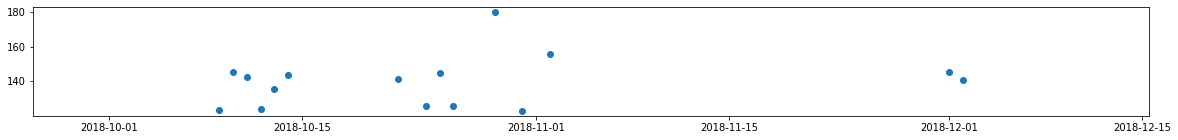

In [40]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_subset = df_vitals_sbp_day[df_vitals_sbp_day['patient_uuid'] == 82591262]
df_vitals_subset = df_vitals_subset[['reading_date','SBP']]
pyplot.scatter(df_vitals_subset['reading_date'],df_vitals_subset['SBP'])
pyplot.show()

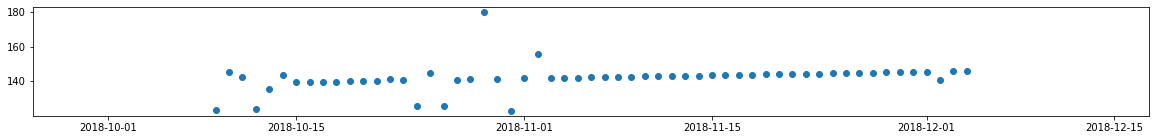

In [41]:
fig = pyplot.figure(figsize=(20, 2))
df_vitals_interpolated_subset = df_vitals_interpolated_final[df_vitals_interpolated_final['patient_uuid'] == 82591262]
df_vitals_interpolated_subset = df_vitals_interpolated_subset[['reading_date','SBP']]
pyplot.scatter(df_vitals_interpolated_subset['reading_date'],df_vitals_interpolated_subset['SBP'])
pyplot.show()

In [42]:
df_vitals_interpolated_final.to_csv("vitals_sbp_interpolated.csv", index = False)